In [1]:
%pip install pandas requests matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

BASE_URL = "https://api.openf1.org/v1"
ANIO = 2025

In [3]:
# 1. Buscar la última carrera de 2024
respuesta = requests.get(
    f"{BASE_URL}/sessions",
    params={
        "year": ANIO,
        "session_name": "Race",
        "country_name": "United Arab Emirates"
    },
    timeout=30
)
respuesta.raise_for_status()

sesiones = pd.DataFrame(respuesta.json())

if sesiones.empty:
    raise ValueError("No se encontró la carrera final de 2024.")

sesion = sesiones.sort_values("date_start").iloc[-1]
session_key = int(sesion["session_key"])

In [4]:
# 2. Obtener la clasificación final del campeonato de pilotos
respuesta = requests.get(
    f"{BASE_URL}/championship_drivers",
    params={"session_key": session_key},
    timeout=30
)
respuesta.raise_for_status()

datos = pd.DataFrame(respuesta.json())

if datos.empty:
    raise ValueError("La API no devolvió la clasificación de pilotos.")

print("Columnas recibidas:", datos.columns.tolist())

Columnas recibidas: ['meeting_key', 'session_key', 'driver_number', 'position_start', 'position_current', 'points_start', 'points_current']


In [5]:
# 3. Comprobar y preparar los datos
columnas = {"position_current", "driver_number", "points_current"}

if not columnas.issubset(datos.columns):
    raise ValueError(
        "La API no devuelve las columnas esperadas. "
        "Revisa los nombres impresos arriba."
    )

datos = datos.copy()
datos["points_current"] = pd.to_numeric(
    datos["points_current"], errors="coerce"
)
datos["position_current"] = pd.to_numeric(
    datos["position_current"], errors="coerce"
)
datos = datos.dropna(
    subset=["points_current", "position_current"]
)


In [6]:
# 4. Obtener los nombres de los pilotos
respuesta = requests.get(
    f"{BASE_URL}/drivers",
    params={"session_key": session_key},
    timeout=30
)
respuesta.raise_for_status()

pilotos = pd.DataFrame(respuesta.json())

if {"driver_number", "full_name"}.issubset(pilotos.columns):
    pilotos = pilotos[["driver_number", "full_name"]].drop_duplicates(
        "driver_number"
    )
    datos = datos.merge(pilotos, on="driver_number", how="left")
    datos["full_name"] = datos["full_name"].fillna(
        "Piloto " + datos["driver_number"].astype(str)
    )
else:
    datos["full_name"] = "Piloto " + datos["driver_number"].astype(str)


In [7]:
# 5. Asignar los niveles según los puntos
def asignar_nivel(puntos):
    if puntos > 400:
        return 1
    elif puntos > 200:
        return 2
    elif puntos > 50:
        return 3
    else:
        return 4

datos["nivel"] = datos["points_current"].apply(asignar_nivel)

# Ordenar por nivel y posición
datos = datos.sort_values(
    ["nivel", "position_current"]
).reset_index(drop=True)

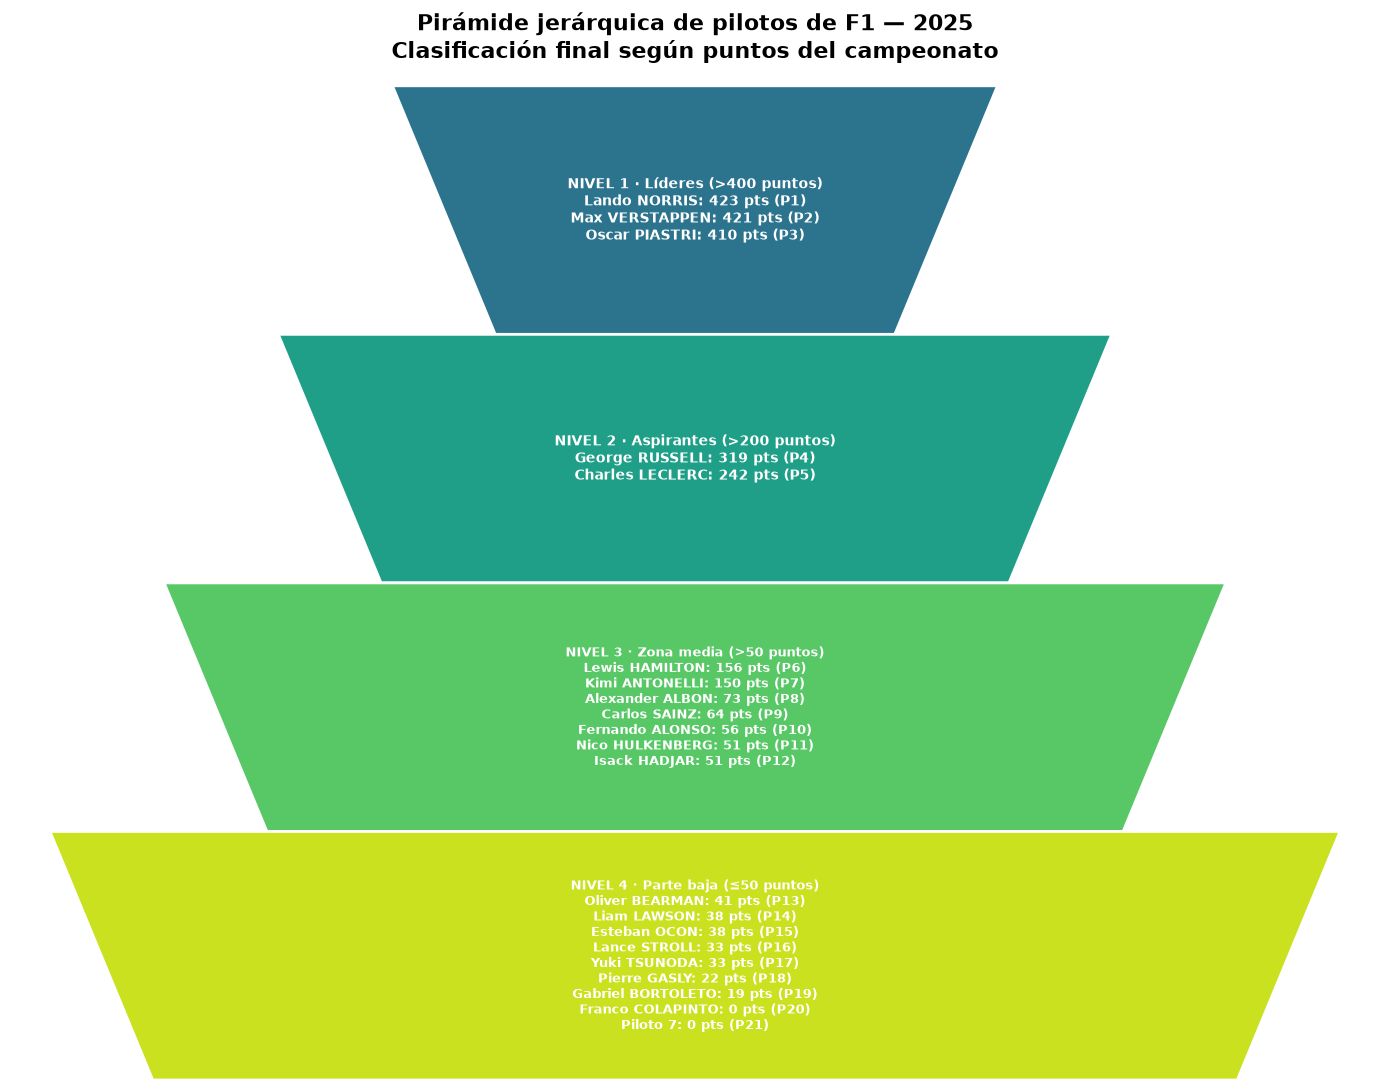


Clasificación final por niveles:
 position_current         full_name  points_current  nivel
                1      Lando NORRIS           423.0      1
                2    Max VERSTAPPEN           421.0      1
                3     Oscar PIASTRI           410.0      1
                4    George RUSSELL           319.0      2
                5   Charles LECLERC           242.0      2
                6    Lewis HAMILTON           156.0      3
                7    Kimi ANTONELLI           150.0      3
                8   Alexander ALBON            73.0      3
                9      Carlos SAINZ            64.0      3
               10   Fernando ALONSO            56.0      3
               11   Nico HULKENBERG            51.0      3
               12      Isack HADJAR            51.0      3
               13    Oliver BEARMAN            41.0      4
               14       Liam LAWSON            38.0      4
               15      Esteban OCON            38.0      4
               16     

In [ ]:
# 6. Dibujar la pirámide: Nivel 1 arriba, Nivel 4 abajo
configuracion = [
    (1, "NIVEL 1 · Líderes (>400 puntos)", 3.5),
    (2, "NIVEL 2 · Aspirantes (>200 puntos)", 5.5),
    (3, "NIVEL 3 · Zona media (>50 puntos)", 7.5),
    (4, "NIVEL 4 · Parte baja (≤50 puntos)", 9.5)
]

fig, ax = plt.subplots(figsize=(14, 11))
altura = 2.0

for nivel, titulo_nivel, ancho_inferior in configuracion:
    grupo = datos[datos["nivel"] == nivel]

    # La coordenada más alta corresponde al nivel 1
    y_inferior = (4 - nivel) * altura
    y_superior = y_inferior + altura

    ancho_superior = ancho_inferior + 1.8

    vertices = [
        (-ancho_inferior / 2, y_inferior),
        (ancho_inferior / 2, y_inferior),
        (ancho_superior / 2, y_superior),
        (-ancho_superior / 2, y_superior)
    ]

    poligono = Polygon(
        vertices,
        closed=True,
        facecolor=plt.cm.viridis(0.20 + nivel * 0.18),
        edgecolor="white",
        linewidth=2
    )
    ax.add_patch(poligono)

    if grupo.empty:
        texto = titulo_nivel + "\nSin pilotos en este nivel"
    else:
        lineas = [
            f"{fila.full_name}: {fila.points_current:g} pts "
            f"(P{int(fila.position_current)})"
            for fila in grupo.itertuples()
        ]
        texto = titulo_nivel + "\n" + "\n".join(lineas)

    ax.text(
        0,
        (y_inferior + y_superior) / 2,
        texto,
        ha="center",
        va="center",
        color="white",
        fontsize=9 if len(grupo) > 4 else 10,
        fontweight="bold"
    )

# 7. Formato final
ax.set_xlim(-6, 6)
ax.set_ylim(0, 4 * altura)
ax.set_aspect("auto")
ax.axis("off")

ax.set_title(
    f"Pirámide jerárquica de pilotos de F1 — {ANIO}\n"
    "Clasificación final según puntos del campeonato",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.tight_layout()
plt.savefig(
    "piramide_pilotos_f1_2025.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nClasificación final por niveles:")
print(
    datos[
        ["position_current", "full_name", "points_current", "nivel"]
    ].to_string(index=False)
)
